<a href="https://colab.research.google.com/github/Paxlawa/Labu/blob/main/%D0%9B%D0%A0_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Дисципліна: Машинне навчання
Прізвище, ім’я: Говоруха Євген
Група: 4-9
Дата: 19.11.2026

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    'Футболка', 'Штани', 'Светр', 'Сукня', 'Пальто',
    'Сандалі', 'Сорочка', 'Кросівки', 'Сумка', 'Черевики'
]

print("x_train:", x_train.shape)
print("y_train:", y_train.shape)
print("x_test:", x_test.shape)
print("y_test:", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train: (60000, 28, 28)
y_train: (60000,)
x_test: (10000, 28, 28)
y_test: (10000,)


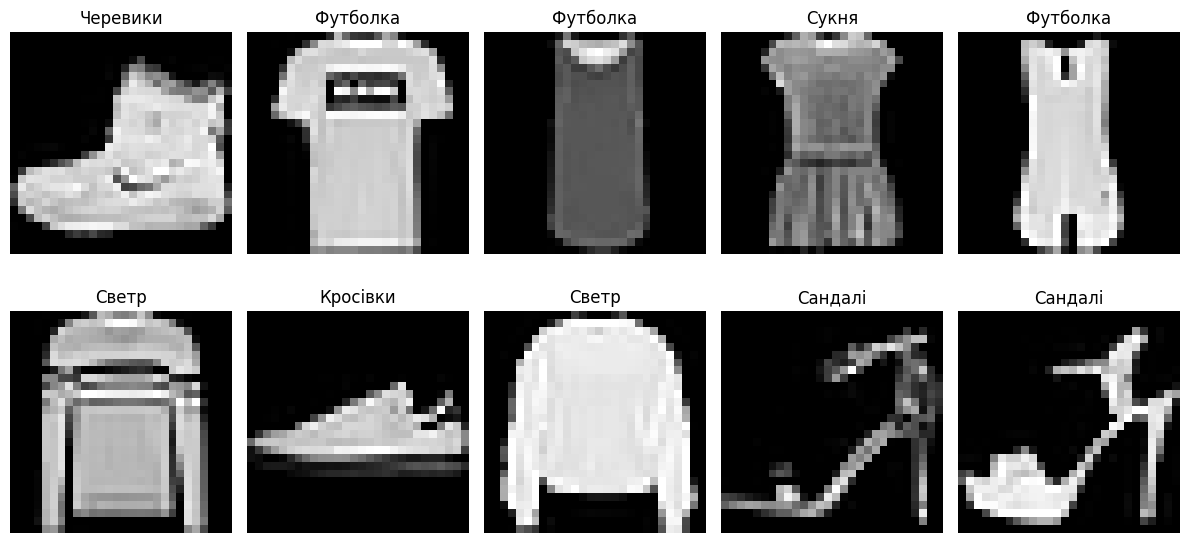

In [3]:
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [4]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print("Мінімальне значення:", x_train.min())
print("Максимальне значення:", x_train.max())
print("Тип даних:", x_train.dtype)

Мінімальне значення: 0.0
Максимальне значення: 1.0
Тип даних: float32


In [5]:
x_train_part, x_val, y_train_part, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.1,
    random_state=42,
    stratify=y_train
)

print("Навчальна вибірка:", x_train_part.shape)
print("Валідаційна вибірка:", x_val.shape)

Навчальна вибірка: (54000, 28, 28)
Валідаційна вибірка: (6000, 28, 28)


In [6]:
model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),

    layers.Dense(512, activation='relu'),
    layers.Dropout(0.2),

    layers.Dense(256, activation='relu'),
    layers.Dropout(0.2),

    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 535,818 (2.04 MB)

 Trainable params: 535,818 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

history = model.fit(
    x_train_part,
    y_train_part,
    epochs=30,
    batch_size=128,
    validation_data=(x_val, y_val),
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.8056 - loss: 0.5426 - val_accuracy: 0.8645 - val_loss: 0.3723 - learning_rate: 0.0010
Epoch 2/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.8536 - loss: 0.3958 - val_accuracy: 0.8660 - val_loss: 0.3486 - learning_rate: 0.0010
Epoch 3/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 11s 26ms/step - accuracy: 0.8682 - loss: 0.3609 - val_accuracy: 0.8797 - val_loss: 0.3332 - learning_rate: 0.0010
Epoch 4/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - accuracy: 0.8759 - loss: 0.3351 - val_accuracy: 0.8848 - val_loss: 0.3131 - learning_rate: 0.0010
Epoch 5/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 24ms/step - accuracy: 0.8823 - loss: 0.3173 - val_accuracy: 0.8873 - val_loss: 0.3096 - learning_rate: 0.0010
Epoch 6/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 11s 25ms/step - accuracy: 0.8862 - loss: 0.3045 - val_accuracy: 0.8922 - val_loss: 0.3015 - learning_rate: 0.0010
Epoch 7/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.8908 - lo

In [8]:
model.summary()

print("Кількість шарів:", len(model.layers))
print("Загальна кількість параметрів:", model.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,607,456 (6.13 MB)

 Trainable params: 535,818 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,071,638 (4.09 MB)

Кількість шарів: 6
Загальна кількість параметрів: 535818


In [9]:
model.save('fashion_mnist_model.keras')

print("Модель успішно збережена!")

Модель успішно збережена!


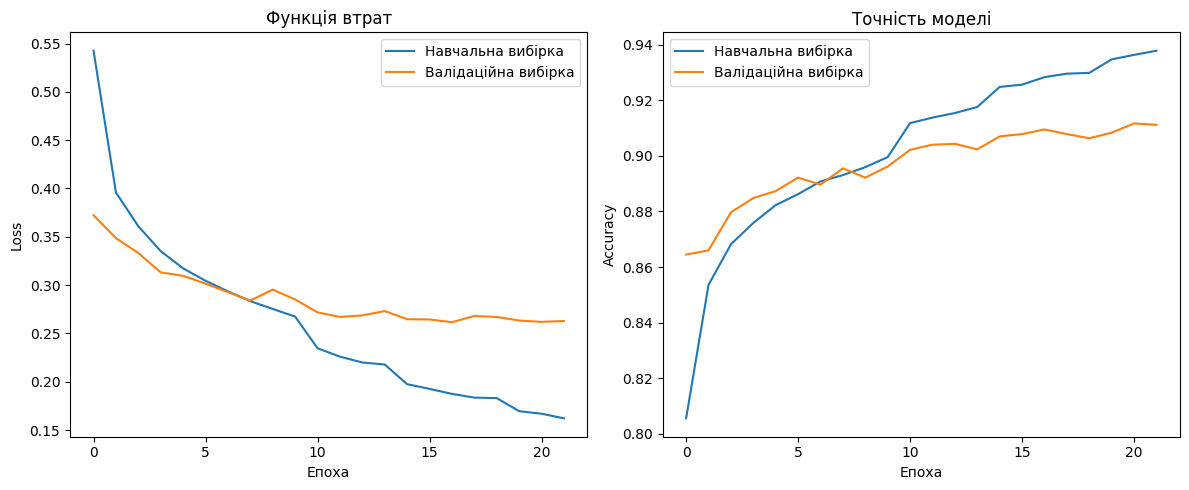

In [10]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Навчальна вибірка')
plt.plot(history.history['val_loss'], label='Валідаційна вибірка')
plt.title('Функція втрат')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Навчальна вибірка')
plt.plot(history.history['val_accuracy'], label='Валідаційна вибірка')
plt.title('Точність моделі')
plt.xlabel('Епоха')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [11]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Точність у відсотках:", test_accuracy * 100)

y_pred = np.argmax(model.predict(x_test), axis=1)

print(classification_report(
    y_test,
    y_pred,
    target_names=class_names
))

if test_accuracy >= 0.87:
    print("Вимогу щодо точності виконано!")
else:
    print("Вимогу щодо точності не виконано.")

Test Loss: 0.3031717836856842
Test Accuracy: 0.8956000208854675
Точність у відсотках: 89.56000208854675
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
              precision    recall  f1-score   support

    Футболка       0.84      0.87      0.86      1000
       Штани       0.99      0.97      0.98      1000
       Светр       0.81      0.82      0.81      1000
       Сукня       0.88      0.92      0.90      1000
      Пальто       0.80      0.83      0.81      1000
     Сандалі       0.98      0.97      0.98      1000
     Сорочка       0.76      0.67      0.71      1000
    Кросівки       0.95      0.97      0.96      1000
       Сумка       0.98      0.97      0.98      1000
    Черевики       0.97      0.96      0.96      1000

    accuracy                           0.90     10000
   macro avg       0.89      0.90      0.89     10000
weighted avg       0.89      0.90      0.89     10000

Вимогу щодо точності виконано!


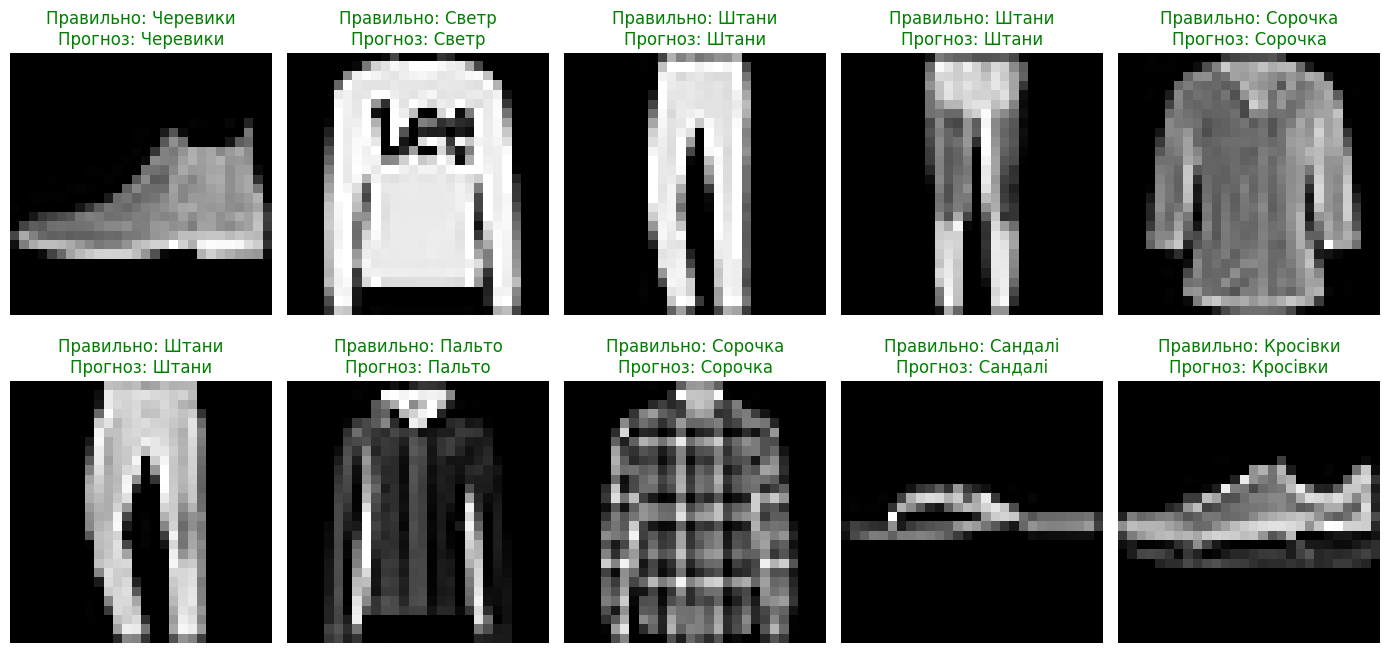

In [12]:
plt.figure(figsize=(14, 7))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[i], cmap='gray')

    color = 'green' if y_pred[i] == y_test[i] else 'red'

    plt.title(
        f"Правильно: {class_names[y_test[i]]}\n"
        f"Прогноз: {class_names[y_pred[i]]}",
        color=color
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

In [13]:
!pip install -q keras-tuner

In [14]:
import keras_tuner as kt

from tensorflow.keras.regularizers import l2
from tensorflow.keras.layers import Dense, Flatten, Dropout

print("Keras Tuner version:", kt.__version__)

Keras Tuner version: 1.4.8


In [15]:
print("Навчальна вибірка:", x_train_part.shape)
print("Валідаційна вибірка:", x_val.shape)
print("Тестова вибірка:", x_test.shape)

Навчальна вибірка: (54000, 28, 28)
Валідаційна вибірка: (6000, 28, 28)
Тестова вибірка: (10000, 28, 28)


In [16]:
def build_model(hp):

    model = keras.Sequential()

    model.add(Flatten(input_shape=(28, 28)))

    num_layers = hp.Int(
        'num_layers',
        min_value=1,
        max_value=3,
        step=1
    )

    for i in range(num_layers):

        units = hp.Int(
            f'units_{i}',
            min_value=32,
            max_value=512,
            step=32
        )

        dropout_rate = hp.Float(
            f'dropout_{i}',
            min_value=0.1,
            max_value=0.5,
            step=0.1
        )

        model.add(Dense(
            units,
            activation='relu',
            kernel_regularizer=l2(0.001)
        ))

        model.add(Dropout(dropout_rate))

    model.add(Dense(10, activation='softmax'))

    learning_rate = hp.Choice(
        'learning_rate',
        values=[0.01, 0.001, 0.0001]
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [17]:
tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=3,
    executions_per_trial=1,
    directory='fashion_tuner',
    project_name='fashion_mnist'
)

tuner.search_space_summary()

Search space summary
Default search space size: 4
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
dropout_0 (Float)
{'default': 0.1, 'conditions': [], 'min_value': 0.1, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [18]:
early_stop_tuner = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr_tuner = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

tuner.search(
    x_train_part,
    y_train_part,
    epochs=20,
    batch_size=128,
    validation_data=(x_val, y_val),
    callbacks=[early_stop_tuner, reduce_lr_tuner]
)

Trial 3 Complete [00h 01m 48s]
val_accuracy: 0.8784999847412109

Best val_accuracy So Far: 0.8871666789054871
Total elapsed time: 00h 04m 15s


In [19]:
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("Найкращі гіперпараметри:")
print("Кількість шарів:", best_hp.get('num_layers'))

for i in range(best_hp.get('num_layers')):
    print(f"Нейрони шару {i + 1}:", best_hp.get(f'units_{i}'))
    print(f"Dropout шару {i + 1}:", best_hp.get(f'dropout_{i}'))

print("Learning rate:", best_hp.get('learning_rate'))

Найкращі гіперпараметри:
Кількість шарів: 1
Нейрони шару 1: 448
Dropout шару 1: 0.30000000000000004
Learning rate: 0.0001


In [20]:
best_model = tuner.get_best_models(num_models=1)[0]

best_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 448)            │       351,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 448)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         4,490 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,170 (1.36 MB)

 Trainable params: 356,170 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
best_model = build_model(best_hp)

history_best = best_model.fit(
    x_train_part,
    y_train_part,
    epochs=30,
    batch_size=128,
    validation_data=(x_val, y_val),
    callbacks=[early_stop_tuner, reduce_lr_tuner]
)

Epoch 1/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.7208 - loss: 1.3672 - val_accuracy: 0.8170 - val_loss: 1.0211 - learning_rate: 1.0000e-04
Epoch 2/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.8148 - loss: 0.9806 - val_accuracy: 0.8442 - val_loss: 0.8713 - learning_rate: 1.0000e-04
Epoch 3/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.8325 - loss: 0.8651 - val_accuracy: 0.8547 - val_loss: 0.7908 - learning_rate: 1.0000e-04
Epoch 4/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.8415 - loss: 0.7925 - val_accuracy: 0.8593 - val_loss: 0.7318 - learning_rate: 1.0000e-04
Epoch 5/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.8484 - loss: 0.7381 - val_accuracy: 0.8645 - val_loss: 0.6809 - learning_rate: 1.0000e-04
Epoch 6/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.8557 - loss: 0.6914 - val_accuracy: 0.8682 - val_loss: 0.6485 - learning_rate: 1.0000e-04
Epoch 7/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - acc

In [22]:
best_test_loss, best_test_accuracy = best_model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("Найкраща модель:")
print("Test Loss:", best_test_loss)
print("Test Accuracy:", best_test_accuracy)
print("Точність у відсотках:", best_test_accuracy * 100)

Найкраща модель:
Test Loss: 0.42305463552474976
Test Accuracy: 0.8763999938964844
Точність у відсотках: 87.63999938964844


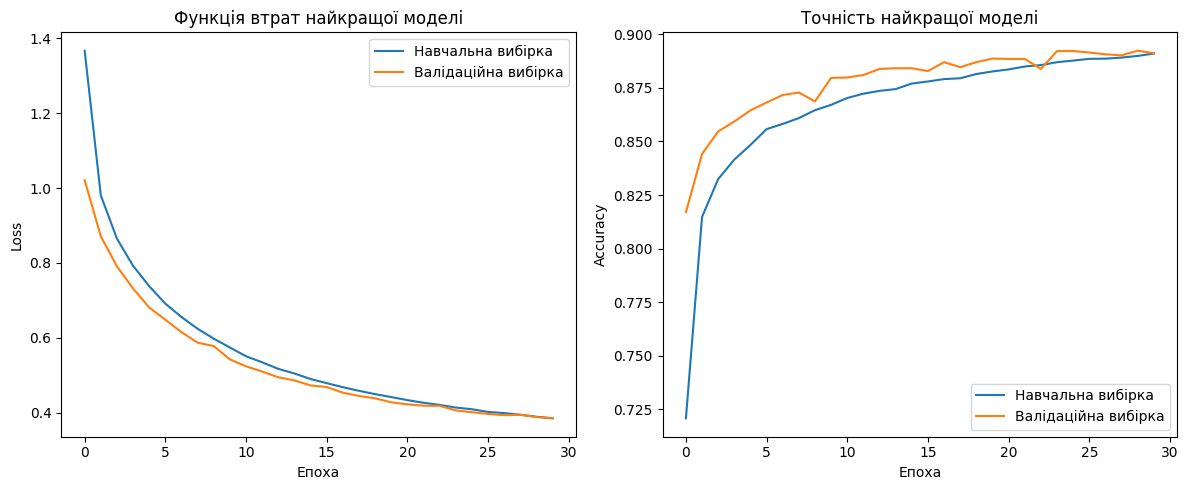

In [23]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_best.history['loss'], label='Навчальна вибірка')
plt.plot(history_best.history['val_loss'], label='Валідаційна вибірка')
plt.title('Функція втрат найкращої моделі')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_best.history['accuracy'], label='Навчальна вибірка')
plt.plot(history_best.history['val_accuracy'], label='Валідаційна вибірка')
plt.title('Точність найкращої моделі')
plt.xlabel('Епоха')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [24]:
best_model.save('fashion_mnist_best_model.keras')

print("Найкращу модель збережено!")

Найкращу модель збережено!
